# HDB resale (data.gov.sg): clustering

20,000 HDB resale sales from January 2017 (data.gov.sg): floor area, remaining lease, storey and price adjusted by the resale price index, ties spread within half a recording step, standardized. No labels (report dataset D8).

Every method is tuned by the shared, label-free rule (`sc4020.tuning`); labels are used only for the
external scores. Sections: dataset loading, one section per method, metrics, visualization. Tables go to
`results/datasets/hdb_resale_results.csv` and `hdb_resale_tuning.csv`, figures to `results/datasets/figures/`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sc4020 import run, tuning
from sc4020.datasets import load_dataset

warnings.filterwarnings("ignore")
np.random.seed(run.SEED)

DATASET_NAME = "hdb_resale"
TOPIC = "datasets"
MAX_CLUSTERS = None  # optional cap on the number of DBSCAN and HDBSCAN clusters

## 1. Dataset loading

In [2]:
ds = load_dataset(DATASET_NAME)
k_range = run.K_RANGES.get(DATASET_NAME, tuning.K_RANGE)
print(ds.DESCR)
print(f"{len(ds.data):,} points, {ds.data.shape[1]} features, classes: {ds.n_true_clusters}")
pd.DataFrame(ds.data, columns=ds.feature_names).describe().round(2)

data.gov.sg HDB resale prices (resale_2026-10-13.csv) adjusted by the resale price index (price_index_2026-10-13.csv): 20,000 sales x 4 features, ties jittered, standardized. No labels.
20,000 points, 4 features, classes: None


,floor_area_sqm,remaining_lease_years,storey_mid,real_price
count,20000.00,20000.00,20000.00,20000.00
mean,0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-2.73,-2.39,-1.37,-1.99
25%,-0.76,-0.83,-0.72,-0.71
50%,-0.13,-0.02,-0.16,-0.17
75%,0.64,1.01,0.49,0.53
max,11.23,1.65,6.40,5.62


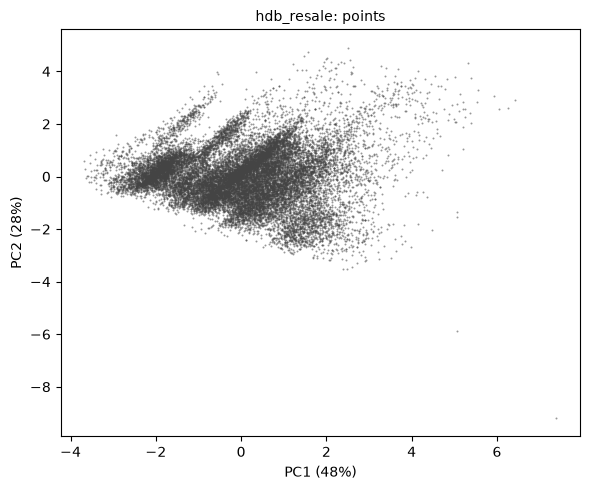

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/hdb_resale_data.png')

In [3]:
from sc4020.generate_figures import plot_coords, scatter_labels, show_and_save

x, y, x_label, y_label = plot_coords(ds)
fig, ax = plt.subplots(figsize=(6, 5))
scatter_labels(
    ax,
    np.column_stack([x, y]),
    ds.target,
    title=f"{DATASET_NAME}: {'classes' if ds.target is not None else 'points'}",
    class_names=ds.get("target_names"),
    size=2 if len(ds.data) > 5000 else 12,
)
ax.set_xlabel(x_label)
ax.set_ylabel(y_label)
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_data")

## 2. Clustering with K-Means

The number of clusters k comes from the fake-data check: for each k, the silhouette on the real data
minus the mean silhouette on copies with every column shuffled, among the k whose seeds agree. On
labelled data K-Means uses the true number of classes, and the label-free choice is shown next to it.
Plain K-Means starts from random centres; K-Means++ (next section) uses the same k.

In [4]:
selections, results = {}, {}
selections["K-Means"] = run.select_method(ds, "K-Means", k_range=k_range)
kmeans_tried = pd.DataFrame(selections["K-Means"].tried)
label_free_k = selections["K-Means"].label_free["n_clusters"]
print(f"k used: {selections['K-Means'].params['n_clusters']}, label-free choice: {label_free_k}")
kmeans_tried.round(3)

k used: 4, label-free choice: 4


,n_clusters,inertia,silhouette,null_silhouette,null_gap,davies_bouldin,smallest_cluster,largest_cluster,mean_seed_ari,min_seed_ari
0,2,54645.258,0.294,0.203,0.091,1.276,8296,11704,0.990,0.974
1,3,42625.247,0.302,0.209,0.093,1.266,5935,7108,0.990,0.979
2,4,33916.023,0.315,0.219,0.096,1.125,1947,7114,0.994,0.986
3,5,29081.337,0.291,0.214,0.078,1.152,1483,5506,0.994,0.988
4,6,25946.060,0.286,0.192,0.094,1.177,869,5108,0.988,0.955
5,7,23642.384,0.292,0.190,0.102,1.108,846,5045,0.956,0.815
6,8,21905.989,0.289,0.193,0.096,1.121,771,4859,0.922,0.782
7,9,20298.086,0.290,0.193,0.098,1.092,620,4674,0.814,0.617
8,10,18827.569,0.260,0.189,0.071,1.155,625,3492,0.914,0.672


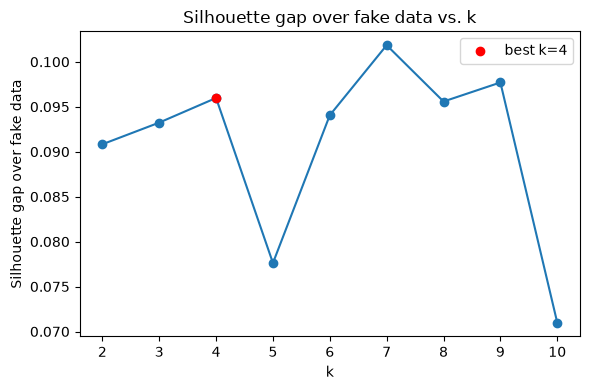

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/hdb_resale_kmeans_k_selection.png')

In [5]:
from sc4020.generate_figures import plot_k_selection, show_and_save

fig = plot_k_selection(
    kmeans_tried["n_clusters"].tolist(),
    kmeans_tried["null_gap"].tolist(),
    best_k=label_free_k,
    ylabel="Silhouette gap over fake data",
)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_kmeans_k_selection")

In [6]:
selections["K-Means (random init)"] = run.select_method(ds, "K-Means (random init)", selections)
results["K-Means (random init)"] = run.fit_method(
    ds, "K-Means (random init)", selections["K-Means (random init)"]
)

## 3. Clustering with K-Means++

In [7]:
results["K-Means"] = run.fit_method(ds, "K-Means", selections["K-Means"])
pd.DataFrame(
    {
        name: {
            "inertia": results[name].model.inertia_,
            "iterations": results[name].model.n_iter_,
            "fit_seconds": results[name].fit_seconds,
        }
        for name in ("K-Means (random init)", "K-Means")
    }
).T.round(3)

,inertia,iterations,fit_seconds
K-Means (random init),33916.234,32.0,0.050
K-Means,33916.023,12.0,0.898


## 4. Clustering with DBSCAN

min_samples follows the dimension, and eps is tried at multiples of the knee of the k-distance curve.
The rule keeps settings with at least 2 clusters and at most half the points as noise, then takes the
highest silhouette.

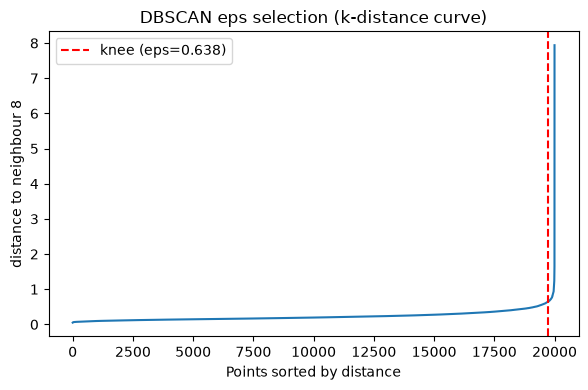

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/hdb_resale_dbscan_k_distance.png')

In [8]:
from sc4020.generate_figures import plot_k_distance, show_and_save

min_samples = tuning.min_samples_from_dimension(ds.data.shape[1])
curve = tuning.k_distance_curve(ds.data, min_samples)
knee_index, eps_at_knee = tuning.find_knee(curve)
fig = plot_k_distance(curve, knee_index, eps_at_knee, min_samples)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_dbscan_k_distance")

In [9]:
selections["DBSCAN"] = run.select_method(ds, "DBSCAN", max_clusters=MAX_CLUSTERS)
results["DBSCAN"] = run.fit_method(ds, "DBSCAN", selections["DBSCAN"])
print(f"chosen: {run.format_params(selections['DBSCAN'].params)}, rule satisfied: {selections['DBSCAN'].valid}")
pd.DataFrame(selections["DBSCAN"].tried).round(3)

chosen: eps=0.614, min_samples=4, rule satisfied: True


,eps,min_samples,eps_factor,n_clusters,noise_fraction,largest_cluster_share,silhouette,passes
0,0.246,4,0.50,110,0.129,0.788,-0.519,True
1,0.369,4,0.75,36,0.029,0.901,-0.135,True
2,0.491,4,1.00,13,0.008,0.975,0.001,True
3,0.614,4,1.25,3,0.002,0.997,0.506,True
4,0.737,4,1.50,2,0.001,0.999,0.506,True
5,0.983,4,2.00,1,0.000,1.000,NaN,False
6,0.319,8,0.50,19,0.105,0.831,-0.298,True
7,0.478,8,0.75,13,0.020,0.960,0.069,True
8,0.638,8,1.00,2,0.004,0.996,0.500,True
9,0.797,8,1.25,1,0.001,0.999,NaN,False


## 5. Clustering with HDBSCAN

In [10]:
selections["HDBSCAN"] = run.select_method(ds, "HDBSCAN", max_clusters=MAX_CLUSTERS)
results["HDBSCAN"] = run.fit_method(ds, "HDBSCAN", selections["HDBSCAN"])
print(f"chosen: {run.format_params(selections['HDBSCAN'].params)}, rule satisfied: {selections['HDBSCAN'].valid}")
pd.DataFrame(selections["HDBSCAN"].tried).round(3)

chosen: min_cluster_size=5, min_samples=None, rule satisfied: True


,min_cluster_size,min_samples,n_clusters,noise_fraction,largest_cluster_share,silhouette,passes
0,5,NaN,2,0.003,0.996,0.509,True
1,5,5.0,2,0.003,0.996,0.509,True
2,5,10.0,8,0.092,0.858,-0.017,True
3,10,NaN,22,0.456,0.176,0.106,True
4,10,5.0,9,0.066,0.880,-0.020,True
5,10,10.0,22,0.456,0.176,0.106,True
6,15,NaN,3,0.110,0.835,0.128,True
7,15,5.0,7,0.067,0.880,0.025,True
8,15,10.0,4,0.121,0.820,0.124,True
9,20,NaN,3,0.091,0.853,0.126,True


## 6. Clustering with GMM

The number of components and the covariance type with the lowest BIC (the number of components is the
number of classes on labelled data).

In [11]:
selections["GMM"] = run.select_method(ds, "GMM", k_range=k_range)
results["GMM"] = run.fit_method(ds, "GMM", selections["GMM"])
gmm_tried = pd.DataFrame(selections["GMM"].tried).rename(columns={"score": "minus_bic"})
print(f"chosen: {run.format_params(selections['GMM'].params)}, label-free: {run.format_params(selections['GMM'].label_free)}")
gmm_tried.pivot(index="n_components", columns="covariance_type", values="minus_bic").round(1)

chosen: n_components=10, covariance_type=full, label-free: n_components=10, covariance_type=full


covariance_type,diag,full,spherical,tied
n_components,,,,
2,-209954.0,-187979.8,-210655.7,-201476.5
3,-195373.8,-179353.6,-204368.5,-193353.3
4,-190480.2,-175863.0,-199456.7,-187774.1
5,-182083.3,-169776.6,-194452.9,-184134.5
6,-178512.8,-167477.2,-192411.4,-183547.8
7,-176705.8,-166004.1,-190590.2,-181163.7
8,-168824.6,-159882.3,-188730.1,-179600.1
9,-166364.1,-164584.5,-185752.2,-179074.5
10,-163145.0,-155163.1,-184966.4,-178138.5


## 7. Clustering with Spectral

Spectral clustering at the K-Means k: an RBF affinity on Wine, a 10-nearest-neighbour graph elsewhere
(`run.SPECTRAL_AFFINITY_BY_DATASET`). A dense RBF affinity needs memory quadratic in the number of
points, so it is skipped on large data; the nearest-neighbour graph is sparse and runs at any size.

In [12]:
if run.is_too_large(ds, "Spectral"):
    print(f"skipping Spectral: {len(ds.data):,} points is above {run.MAX_POINTS_FOR_DENSE_SPECTRAL:,}")
else:
    selections["Spectral"] = run.select_method(ds, "Spectral", selections)
    results["Spectral"] = run.fit_method(ds, "Spectral", selections["Spectral"])
    print(f"Spectral: {run.format_params(selections['Spectral'].params)}")

Spectral: n_clusters=4, affinity=nearest_neighbors


## 8. Metrics

Internal scores (silhouette, Davies-Bouldin, DBCV) need no labels; ARI and NMI compare with the classes
when there are any. Noise points are left out of the internal scores. The null columns refit each
method at its setting on a copy with every column shuffled: a silhouette near the null one means the
clusters are no stronger than on data without structure.

In [13]:
table = run.score_methods(ds, selections, results)
run.save_dataset_run(DATASET_NAME, table, run.tried_settings(ds, selections))
columns = [
    "method",
    "params",
    "n_clusters",
    "noise_fraction",
    "largest_cluster_share",
    "silhouette",
    "davies_bouldin",
    "dbcv",
    "ari",
    "nmi",
    "fit_seconds",
    "null_silhouette",
]
table[[column for column in columns if column in table]].round(3)

,method,params,n_clusters,noise_fraction,largest_cluster_share,silhouette,davies_bouldin,dbcv,fit_seconds,null_silhouette
0,K-Means (random init),n_clusters=4,4,0.000,0.354,0.317,1.125,-0.664,0.050,0.216
1,K-Means,n_clusters=4,4,0.000,0.356,0.318,1.125,-0.696,0.898,0.216
2,DBSCAN,"eps=0.614, min_samples=4",3,0.002,0.997,0.438,0.436,-1.000,0.567,0.189
3,HDBSCAN,"min_cluster_size=5, min_samples=None",2,0.003,0.996,0.496,0.406,-1.000,1.596,0.136
4,GMM,"n_components=10, covariance_type=full",10,0.000,0.158,0.176,1.537,-0.572,1.456,0.088
5,Spectral,"n_clusters=4, affinity=nearest_neighbors",4,0.000,0.671,0.205,1.227,-0.685,2.413,0.167


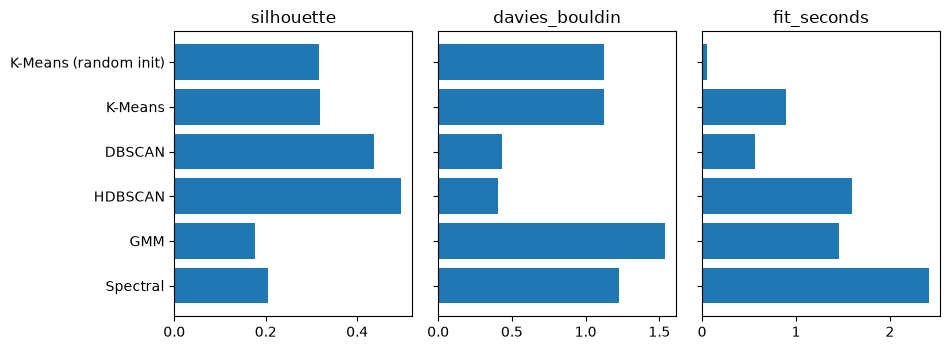

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/hdb_resale_metrics.png')

In [14]:
from sc4020.generate_figures import show_and_save

metric_names = [m for m in ("silhouette", "davies_bouldin", "ari", "fit_seconds") if m in table]
fig, axes = plt.subplots(1, len(metric_names), figsize=(3.2 * len(metric_names), 3.6), sharey=True)
for ax, metric in zip(axes, metric_names):
    ax.barh(table["method"], table[metric])
    ax.set_title(metric)
axes[0].invert_yaxis()
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_metrics")

## 9. Visualization

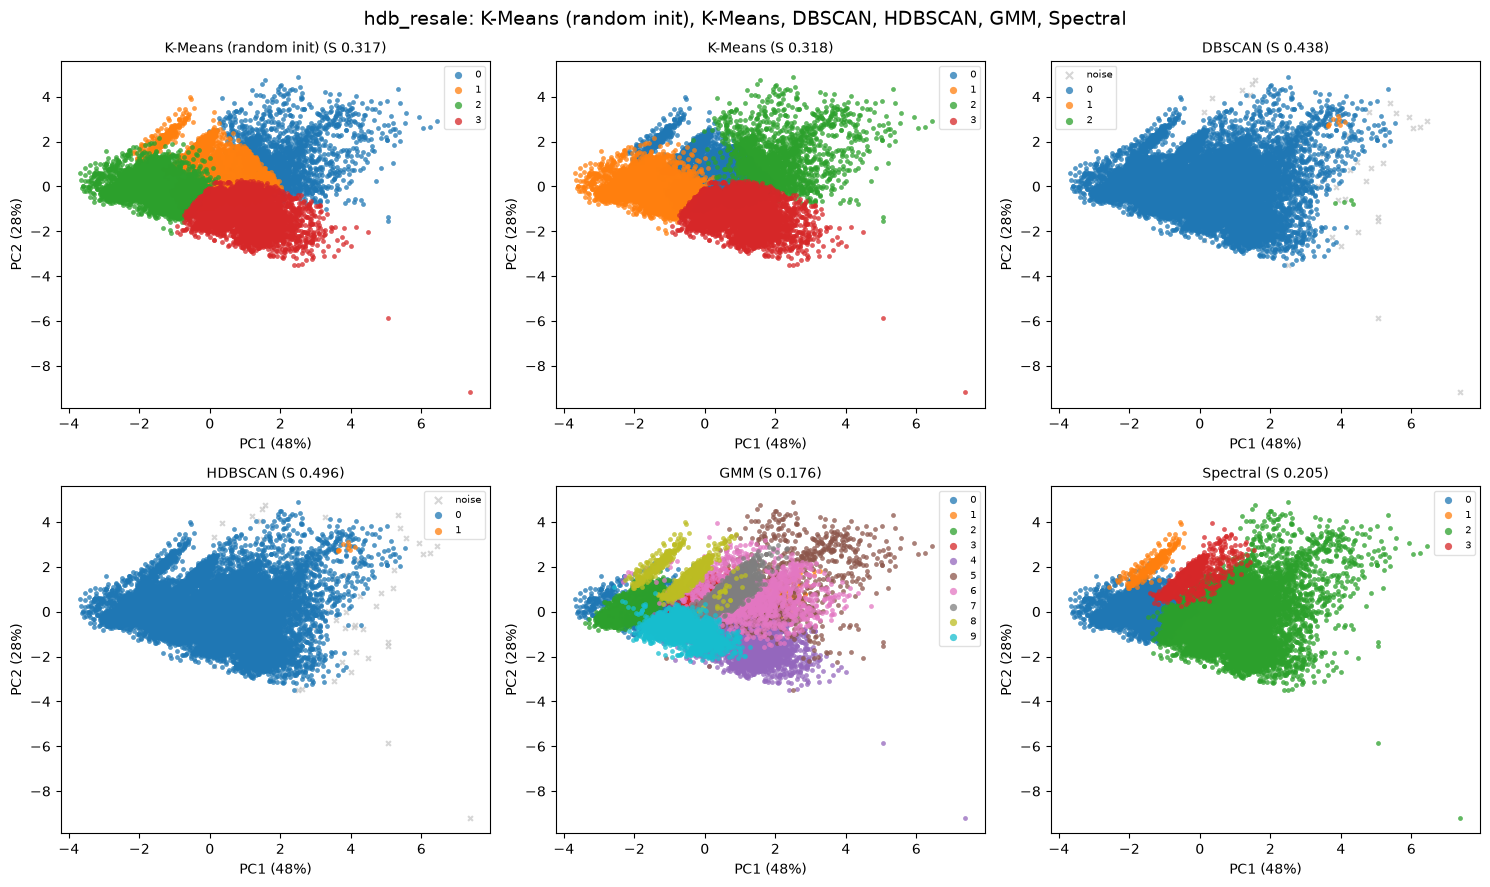

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/hdb_resale_clusters.png')

In [15]:
from sc4020.generate_figures import show_and_save

fig = run.plot_dataset(ds, results, table, title=f"{DATASET_NAME}: {', '.join(results)}")
show_and_save(fig, TOPIC, f"{DATASET_NAME}_clusters")